# Lab 3: Logistic Regression
Task: classify whether a driver's **insurance premium is High (1) or Low (0)** from six driver/car features, using gradient descent with L2 regularization.

In [ ]:
import os
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
# Download latest version
path = kagglehub.dataset_download("govindaramsriram/car-insurance-premium-dataset")

print("Path to dataset files:", path)

100%|██████████| 9.38k/9.38k [00:00<00:00, 13.6MB/s]

Extracting files...
Path to dataset files: /root/.cache/kagglehub/datasets/govindaramsriram/car-insurance-premium-dataset/versions/1


In [ ]:
df = pd.read_csv(os.path.join(path, "car_insurance_premium_dataset.csv"))

In [ ]:
display(df)

,Driver Age,Driver Experience,Previous Accidents,Annual Mileage (x1000 km),Car Manufacturing Year,Car Age,Insurance Premium ($)
0,56,32,4,17,2002,23,488.35
1,46,19,0,21,2025,0,486.15
2,32,11,4,15,2020,5,497.55
3,60,0,4,19,1991,34,498.35
4,25,7,0,13,2005,20,495.55
...,...,...,...,...,...,...,...
995,23,5,3,22,2020,5,500.00
996,43,8,3,17,2023,2,494.55
997,21,3,5,19,1998,27,506.05
998,36,18,1,23,2011,14,491.45


In [ ]:
df.shape

(1000, 7)

In [ ]:
X_columns = df.columns[:-1]
target_col = "Insurance Premium ($)"

## Create binary target
Logistic regression needs a 0/1 label. We label a premium as **High (1)** if it is above the *training-set median*, otherwise **Low (0)**.

In [ ]:
X_train, X_test = df[X_columns].iloc[:800].copy(), df[X_columns].iloc[800:].copy()
prem_train, prem_test = df[target_col].iloc[:800], df[target_col].iloc[800:]

threshold = prem_train.median()
y_train = (prem_train > threshold).astype(int)
y_test = (prem_test > threshold).astype(int)

print("Threshold ($):", threshold)
print("Class balance (train):", y_train.value_counts().to_dict())

Threshold ($): 494.0
Class balance (train): {0: 401, 1: 399}


In [ ]:
print(X_train.shape, X_test.shape)

(800, 6) (200, 6)


In [ ]:
display(y_train)

,Insurance Premium ($)
0,0
1,0
2,1
3,1
4,1
...,...
795,1
796,0
797,0
798,0


## Standardize features
Both sets are scaled with the **training** mean/std, so no test information leaks in.

In [ ]:
mu, sigma = X_train.mean(), X_train.std()
X_train = (X_train - mu) / sigma
X_test = (X_test - mu) / sigma

In [ ]:
display(X_train)
display(X_test)

,Driver Age,Driver Experience,Previous Accidents,Annual Mileage (x1000 km),Car Manufacturing Year,Car Age
0,1.043005,1.623474,0.827919,-0.214558,-0.523901,0.523901
1,0.313503,0.388080,-1.522871,0.690034,1.674954,-1.674954
2,-0.707799,-0.372162,0.827919,-0.666854,1.196942,-1.196942
3,1.334806,-1.417496,0.827919,0.237738,-1.575528,1.575528
4,-1.218450,-0.752284,-1.522871,-1.119149,-0.237094,0.237094
...,...,...,...,...,...,...
795,0.386454,-0.657253,1.415616,1.368478,-1.193118,1.193118
796,-0.561899,0.102989,-1.522871,-0.893002,0.527725,-0.527725
797,1.699557,1.433413,1.415616,1.368478,0.145316,-0.145316
798,1.626607,1.528444,1.415616,1.594625,0.145316,-0.145316


,Driver Age,Driver Experience,Previous Accidents,Annual Mileage (x1000 km),Car Manufacturing Year,Car Age
800,-0.707799,-0.372162,0.240221,0.690034,1.388147,-1.388147
801,0.897105,-0.752284,0.240221,-1.119149,0.910135,-0.910135
802,-0.270098,-0.752284,-1.522871,0.011590,-1.001913,1.001913
803,-0.780749,-0.182102,0.240221,-1.119149,-1.671130,1.671130
804,-1.656151,-1.322466,-1.522871,1.368478,0.336520,-0.336520
...,...,...,...,...,...,...
995,-1.364351,-0.942344,0.240221,0.916182,1.196942,-1.196942
996,0.094653,-0.657253,0.240221,-0.214558,1.483749,-1.483749
997,-1.510251,-1.132405,1.415616,0.237738,-0.906311,0.906311
998,-0.415998,0.293050,-0.935173,1.142330,0.336520,-0.336520


In [ ]:
Xtr, Xte = X_train.values, X_test.values
ytr, yte = y_train.values, y_test.values

## Model
$p = \sigma(Xw + b)$, with $\sigma(z)=\frac{1}{1+e^{-z}}$.  
Loss: binary cross-entropy + L2 penalty. The gradient has the same form as in linear regression, with error $e = p - y$.

In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def metrics(y, p, thr=0.5):
    pred = (p >= thr).astype(int)
    tp = np.sum((pred == 1) & (y == 1)); tn = np.sum((pred == 0) & (y == 0))
    fp = np.sum((pred == 1) & (y == 0)); fn = np.sum((pred == 0) & (y == 1))
    acc = (tp + tn) / len(y)
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return acc, prec, rec, f1, np.array([[tn, fp], [fn, tp]])

In [ ]:
w = np.zeros(Xtr.shape[1], dtype=np.float64)
b = 0.0
lr = 0.1
alpha = 1.0   # L2 strength
N = len(Xtr)
eps = 1e-12
losses = []

for i in range(5000):
    p = sigmoid(Xtr @ w + b)
    e = p - ytr
    db = e.sum() / N
    dw = (1 / N) * (Xtr.T @ e) + (alpha / N) * w
    b = b - lr * db
    w = w - lr * dw

    loss = -np.mean(ytr * np.log(p + eps) + (1 - ytr) * np.log(1 - p + eps)) + (alpha / (2 * N)) * np.sum(w ** 2)
    losses.append(loss)
    if i % 1000 == 0:
        acc, prec, rec, f1, _ = metrics(ytr, p)
        print(f"Iter {i}  Loss: {loss:.4f}  Acc: {acc:.3f}  Precision: {prec:.3f}  Recall: {rec:.3f}  F1: {f1:.3f}")

Iter 0  Loss: 0.6931  Acc: 0.499  Precision: 0.499  Recall: 1.000  F1: 0.666
Iter 1000  Loss: 0.1150  Acc: 0.991  Precision: 0.990  Recall: 0.992  F1: 0.991
Iter 2000  Loss: 0.1042  Acc: 0.993  Precision: 0.992  Recall: 0.992  F1: 0.992
Iter 3000  Loss: 0.1011  Acc: 0.994  Precision: 0.993  Recall: 0.995  F1: 0.994
Iter 4000  Loss: 0.1001  Acc: 0.996  Precision: 0.997  Recall: 0.995  F1: 0.996


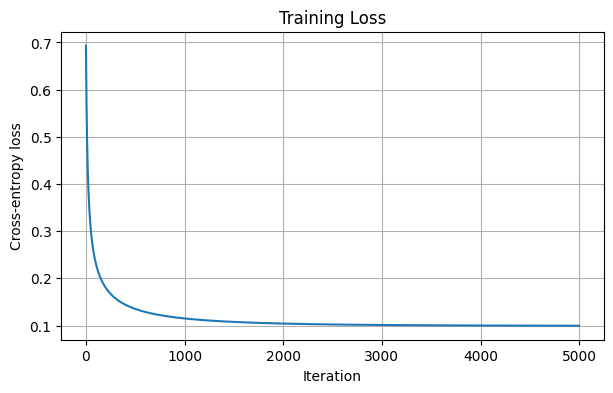

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(losses)
plt.xlabel('Iteration')
plt.ylabel('Cross-entropy loss')
plt.title('Training Loss')
plt.grid(True)
plt.show()

## Evaluation

In [ ]:
def evaluate(X, y, name):
    p = sigmoid(X @ w + b)
    acc, prec, rec, f1, cm = metrics(y, p)
    print(f"{name}: Acc {acc:.3f} | Precision {prec:.3f} | Recall {rec:.3f} | F1 {f1:.3f}")
    return p, cm

p_train, cm_train = evaluate(Xtr, ytr, "Train")
p_test, cm_test = evaluate(Xte, yte, "Test ")

Train: Acc 0.996 | Precision 0.997 | Recall 0.995 | F1 0.996
Test : Acc 0.990 | Precision 0.978 | Recall 1.000 | F1 0.989


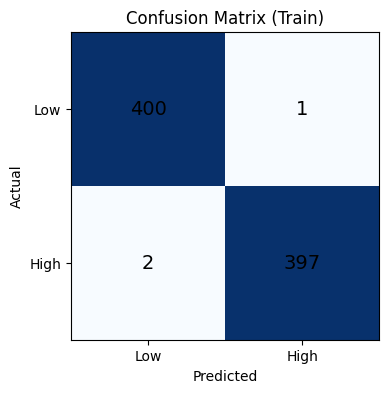

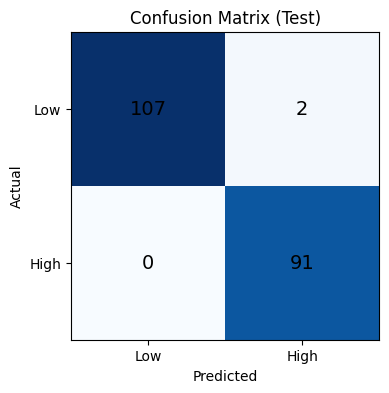

In [ ]:
def plot_cm(cm, title):
    plt.figure(figsize=(4, 4))
    plt.imshow(cm, cmap='Blues')
    for (i, j), v in np.ndenumerate(cm):
        plt.text(j, i, v, ha='center', va='center', fontsize=14)
    plt.xticks([0, 1], ['Low', 'High']); plt.yticks([0, 1], ['Low', 'High'])
    plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title(title)
    plt.show()

plot_cm(cm_train, 'Confusion Matrix (Train)')
plot_cm(cm_test, 'Confusion Matrix (Test)')

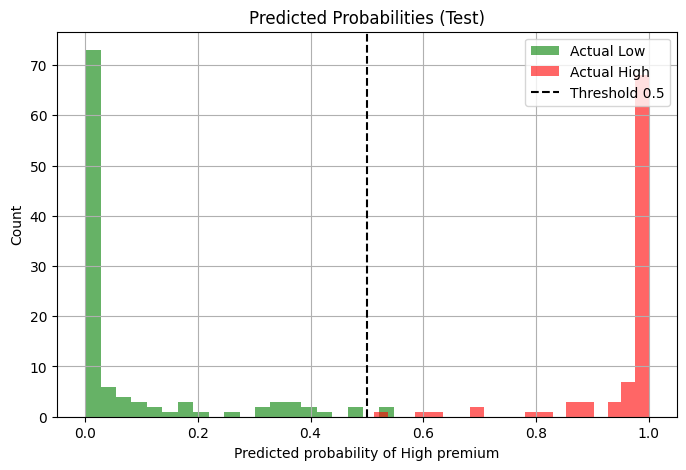

In [ ]:
plt.figure(figsize=(8, 5))
plt.hist(p_test[yte == 0], bins=20, alpha=0.6, label='Actual Low', color='green')
plt.hist(p_test[yte == 1], bins=20, alpha=0.6, label='Actual High', color='red')
plt.axvline(0.5, color='black', linestyle='--', label='Threshold 0.5')
plt.xlabel('Predicted probability of High premium')
plt.ylabel('Count')
plt.title('Predicted Probabilities (Test)')
plt.legend()
plt.grid(True)
plt.show()